# Task 4 — Complete Single-Notebook Submission
**Hazem Daw · Group J4132 · ITMO · Machine Learning Technologies 2026**

**هذا هو ملف التسليم الكامل.** الكود والشرح والصور والنتائج موجودة داخل هذا الملف.
كل الشبكات أدناه هي جزء من الحل الذي نفّذناه؛ عناوين الأقسام توضّح المطلوب الأساسي والإضافة الخاصة بالمسابقة.

| أين الشغل؟ / Section | ماذا عملنا؟ / Work | Measured test accuracy |
|---|---|---:|
| [Part 1 — Required CNN](#part1) | Implemented and trained the specified three-layer CNN | 82.16% |
| [Part 2 — Required transfer learning](#part2) | Implemented VGG16 and ResNet18 transfer learning | 98.32% / **98.56%** |
| [Part 3 — Optional 5A contest](#part3) | Designed and trained a residual CNN **from random initialization** | **96.32%** |
| [Custom image](#custom) | Tested the validation-selected model on a separate dog photograph | Predicted dog |

**جزء الـ5A هو Part 3 فقط:** لم نستخدم فيه أوزانًا جاهزة. نتيجة 98.56% تخص التعلم بالنقل في الواجب الأساسي،
ولا تدخل مسابقة «بدون أوزان مدرّبة مسبقًا». الـ5A التلقائية تعتمد على تحقيق أعلى نتيجة بين المشاركين؛ ليست مضمونة بإكمال الواجب.

## How to use this one file

- **Read / submit:** open this notebook. All photographs, plots and outputs are embedded. No other repository files are needed.
- **Run All to review:** leave both switches below `False`. The notebook rebuilds the charts and tables from the actual saved measurements embedded here. It does not download data or model files.
- **Train again:** set `RUN_TRAINING=True`. The complete training and evaluation implementations are below; the original course dataset and the Part 2 pretrained weights download automatically.
- **Predict a new image:** set `RUN_CUSTOM_INFERENCE=True` and optionally set `CUSTOM_IMAGE_PATH`. The selected checkpoint downloads automatically and is verified by SHA-256.

Training ran on an RTX 3060. Reviewing saved results works on CPU. The original run remains identified as recorded evidence;
new training runs can differ numerically. Dataset archives and large weights are external downloads only when needed, as in a normal ML notebook.

Dependencies: `torch`, `torchvision`, `numpy`, `pandas`, `matplotlib`, `Pillow`, `scikit-learn`; `gdown` is needed only for downloading the training data.
Google Colab already provides most of these. If needed, install with `%pip install torch torchvision numpy pandas matplotlib Pillow scikit-learn gdown`.

In [1]:
from pathlib import Path
import os, io, csv, json, math, random, time, hashlib, shutil, zipfile, contextlib, base64, zlib
from concurrent.futures import ThreadPoolExecutor
import urllib.request
import torch  # Import before plotting extensions on Windows.
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
import torchvision
from torchvision import datasets, transforms, models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report

RUN_TRAINING = False
RUN_CUSTOM_INFERENCE = False
CUSTOM_IMAGE_PATH = None  # e.g. '/content/my_dog.jpg'; None uses the demonstrated dog image.
ROOT = Path.cwd() / 'task4_runtime'  # Used only if training/inference is enabled.
WORKERS = 0 if os.name == 'nt' else 2  # Notebook-safe: Windows cannot spawn notebook-defined workers.
os.environ.setdefault('TORCH_HOME', str(ROOT / '.cache' / 'torch'))
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
FILE_ID = '1lPLlLKhRXvtCG4SNXYflIiy09DMqqPkN'
ARCHIVE_SHA256 = '540915915226479357a1e738bd920c3e19e5a3d8fc56c0622dffa5d682e3631c'
get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18})
print('Mode:', 'RETRAIN all models' if RUN_TRAINING else 'REVIEW the recorded experiments')
print('PyTorch:', torch.__version__, '| GPU available:', torch.cuda.is_available())

Mode: REVIEW the recorded experiments
PyTorch: 2.11.0+cu128 | GPU available: True


### Recorded measurements, not simulated outputs
The next cell stores the original configurations, per-epoch measurements, test metrics, confusion matrices,
checkpoint hashes and custom-image result **inside this notebook**. Compression keeps the one-file submission small.
This is data only: all model and training code is shown normally below. The previous experiment was verified against
all 10,000 per-image predictions (2,500 images × 4 models); reorganizing the submission does not change any score.

In [2]:
# Actual recorded results, compressed JSON; no executable code in this payload.
RECORDED = json.loads(zlib.decompress(base64.b64decode(
    """
eNrtnG9zW8lx7r8Ki6+SCkXN/z97Xzn2Ta7r2i5X7Ep8y9pSgQAoIUuRDEhqvXbpu+f39ByAIAhQq43iF7nm2hJ1zsHpmZ6e7ufp
7sFfTmcPi9X96Tcnfzm9v7mfXfFbSL27s5PT+c3D9f3duLW8u389n9m/fMi6a5cWN+92L61nq+vtY46f7cXNg9PFj7Orx9elzZWd
t33i0sP1ejlbzC6ulm9XH2bvlrqnRxcPt1crPr18+25983Cry3/84+MQ9ce5d7G483+/fXf6ZFx2L8aU7da3Zyd/fJyH/uBzyfnt
5/Zu1V6fvnJ7L7Rad175VF6IsW8+t5n4GCRTb0c/VnyKR2ZQgkv7n3sciwvHhhldC+Nz32p91zd3d2/vUOb9261O/0doU7O7u3lY
z5fM5vT9/f3t3TevXy/Wq4/L83c3N++ulufzmw+vL1dXy9eL1/7qt7+6+tX/ff8vf/h4//N/Tr/7zR/+3+XVL1c/uP6LX//Hf/z2
u9+8/rhafn8qk7xbXi3n96uba9sVF8zo7er6crleXs+Xbz/cLJbaP6fr5d318t63091PvF0/XNlwrm6+53MnjH21mOnOyT/+/H+f
XCwvb9bLEynpZDafL+/u9Gl75diC8+sh9Hr2wV6jf/OEjWF5ezN/z8U+dDK99+0V66s9cx579jmn0FtyrtW9xxD3sJ7Nf7BHW6jR
dXZgi764JDN5v5x/d3uzur5/e/d+FnKR9NmstkW9zC7WWbsI8aIsS5mVVLK/XM4QE1or/nKxzMuwrL3XGuYLBpCqu5jlxaWt+v2M
V13Oru6W0u1Wa7uz3FXlk6l6f2SuLsbSWmcAOXXfU0wvzLa3mrPz+LvoG+o5Nt0LXy8ve27z+WXil8VFivliuWxlmeZpEVFAWqCE
ML+Mzi0vks81zJazyzpfXJb5rB2Y7t18Pbu3qTzOdnNtf7L52GQ9e93ngOWHWph4fWmuhdl2Ftb5lnqsx+a6iP1y3mLpfT7L88sQ
ZzHM533O5XpZZtEvZyHOY10E5y7n/jK0eUUxZZ6xiD53j3O9Xz8snw7o9oq9vDN8H3wPjkUKhVUIe4bJW16YqpT48d07X56ocFx5
Zi3HjCX5gFFGl1txvZeQXzYWn1rGTmKO/BxTIJvn0nf2GZZRZoEhL3y5qHEZZhdtdhl8YIOEOZO+WM7iMuVlnJdwUR0bbxEv076x
fPpkwfjD7Wy9umNQ87uPEmO+4ex2vTQHuVycPc74bG+uZ3Ir47fNjM4uZlczvNZiO8ezS/8W73u2vpm/nT3Mz+Y36zWua3x2BOCz
+apn3vP9+OX96t37M0b65hpndPZPGuxZPzvgbrjEjFPgH8WF4nMsZ3I1/ulfKVdfco2B1fBc6q7WmGLf/JwFl9MZ6nV63hVMIjfe
5X3t9gr96opz7M7WfBtDenO9cSJnv5dBer36gJeQNcQYGAb/j1pmDby3XJ78lWvpITr70wbJtR7OQirboXW2WOiZcFQZZUh2Ce+B
tRHZHHNKm6FNO35SXtYLn+9pbRQNlyiMK8VaW9YrSwzTX+7xx49LMZXCJFJu3l7Qu+cXFx9Vyei2483yCrUhJHXQ39lwFr3qQx4Y
0qup7s217a5JjWcHt48uNtdSaoG3lgB0sOmPsW7/krQSavWoZdJikivYziIw9O34MIPKUjGmrBU6G46bWIKXYkdiLJM6tXXmD3f3
Nx/MKRyMyOyYxcpCsmGdv5yabZvnA3tMyGJ6iO0xv5qZszg1dGo78fpytVDEHwETI489EDcZU6nePnxzMbtYgatWyyl4D6yrhcy9
uOprwERi6Hp8gr3PX/Xp07efnjiZLRI4vx2Q/esG5IsfBv7DciuGKgi+vtpFUO9W9+8fLgw7/Z/Zn5cffjH7/vWvf/X7V7+f3X33
Kr2ya690cQ3qmd0tBee+v766mS1ef/Tn7vU08t1o/3wmXyPWbmaScmQ7p/71p7I7/p1w/nw6XyOcbqbjXSuhpfz1p7Mz/G1cfT6X
rxHZNnNhGnio/465bAdvgXN5/XG1vrn+sLwes7n94f694ffTyG48zyd/dz+Dd3wc//oG6F0uZhjMzx7ewYRPYFMEep++ie2bmP7+
5I+//t3PTz6e+x7LSUknF6v7k7/72a9/UdLff2t+42p2D5CX+zn9t9U1A7t75R3/O3fnoWCwr373W1vS29n8u4nTinmvDaacBg3C
/cP8wYeBGXXj4+puMI5TvWP39vXDh9sfxufSeRmvvV7M7sbs3Hk2DjG7v726ub9aXWwnHYyZzFffre5focK1vdyf93OvG79dXRHi
7VI45zUm6UKzmkmFp1mv8OPq/Go1FHvqbOi6urr94bvl+np43nIeMvLMjz0sZtNb23DUC+M0xF9LCry7fdDt3/zrL3/xy5+d/PPy
n5j88uRffv+Hk0hQH2RqudCuDp8OcyNzze8O0aT1w/XbvUuGlGxX5d1XawIKCG/vVn9e2l2N7UK7Y3spGFFQYHh7f/N2tfjTEyf/
6NL9pxFKJoS2QXQbxvuY1oCB9D3oub2H+9Irl3+aXz0sCEj20dX1uz3O/hJPPkbZX8gsvMDKX8oraO7Lj6tBvG3Bf9TCHt0Au4T7
9APz/vDwYY86n53cv8cbv7+5Wpxcrv60XJzM7k8m2wcys+j3y7UpOQJzfN0M3xJLRx64Wg964BSfv1+Cc+/fLpbz2SACWo7Zwzu5
lNlmbNc318utZrQ6d0uscTEt4LkvDViThG2QILN4vwKmrH/YoPmB24dZDMhuv27BOXMe1/XL9qptXknDey/PJpFvroWoSi6hF1CW
j82B8HQJVJ5jA2bU4IHDXHEZ6htDBSe4XIVUC8jDlcY/WXAv7CgtJHxjziF7QbQUfXxzLRgGeAN6J1B9yQAzQeTSaw4pNo/QUKOk
gCe8A6+1AIpNRfiyQqIAQam2UjMxYxITwrnrkecyG6K2mN9cCz4SxYHpDL0TYnKSGBBhA0eLKTD2qHFmICiQCkSYQub9eio1Nhb/
IYT/5UmMrwyAAbOz+Mk9pTfXmrvQbwSkO9AoAC3aKwqAA4CbkQMElewEFEeKK2A04IUNp5SACoHdNedukHaaD7pC102gu9b+5lpj
SHodUBbAC0+omj2Ay3fBe1xB7UY9UomMEi7A0IHWJqYV9m5EFqjfFGlS+AvVsOLMBv5SWB0bJzwmBNa6u1SarSWD7g7FZ61hNmrG
b1nkRKSGXdftKVYM24BvFP4KO3K8iJHcFVC+Iqca32OdwfS+NshUyYPNeT4IgUE4cNbksCxQI1ECN7QGo2FBoWquQRdK2yxPP4f/
AO1lBa3Dgd5c614smAYkEbWIh0ejfK2AqIvkQkUkxicNo9QmazBG0rDa1Ey9Af65tQJMpqC4mk1tsTEd46ooIml2GLbztpZQPCcz
L75jifUIyd3PnU1iiLcoB6aJGCbA9hSpibI7/F+T1lllfR6OJ2bAZe2XYEvIXoA7YhfQYttNEFtXmVhHh/CzviPGuJozS0NFCNJb
Q20sNB+KKCk2swKUUR3Wjm0ziWpqCyggiA+zOCy9zSelblwBylJDfZRU2By1NDMD6CySNFj2U9N8SumYdh6671qwom0FbbV3JNbR
KHRoPnXWy0SJytWSc2HsfWeJYpTPEnGFTWeJ0tAwa0aHzWQskqW3bEFAaAXwxzBZB5SyaMOweNwpw2ASNBdiXPBd3jIPEtQhmaCz
Zg4Bbs9GtXFh6UgnvEWNFDuTII+L5F9duYMSx5Q8bpFHUtAOtccwTWg8mxeB7O72OCUcC1OUqFjxqIjSfNk9Hq+C7rQRi/kvbWps
Ca/GEIbyioPWYzsdMd7SJEp74AkLj2IUvT4KwiPIcqU7xpAHPybcrVfzu6cEecJEB7HKT00xb5NO44FnGSCC6NPMsy+GtPbyUrs3
R4pqc+VpvgiQNzJXI1m3nzsScbeEliKy8kjTAB9xVjYUuklxDSH7SabpvjJf44H9lNOT1N0GJa4uhdOsCIAe1/e7cPEvUvp8A/Ft
XmJ5eBrMDkswrjyfXV1Nd0MyPby6YzrLzScqvgCbwN7we4JND7eTHBXTzq2cNmHS5/JwG9h4KuPPfXmuHZC3r/lD8g6t34fZfH1z
Mvv47vDE0WNTVoSAUJ8NZDKApwNhHzSlZHEo9ck4tJpjHAO+CRb+t4gt7YhckZEHiXkLb1qv/mSFNayJ52HOKm3ZWnKlfPvtSPI+
prMPMJltZnuXy2wv/kg2M8znCZsp6aeSmSm//zcu89fnMuzZSEjux8lMSYTY5HfJzFdhMzGeV4W6KEJDLMp/DTID1I627bJBEdcs
Kwy21K6NyhX7o/noZ2WbSRXxXFAUZCT0BxIpg9KA+FQhc2Afxas8stMgmMbLBV3xeUMUERVwgDLA93Vkua2cmPCLgP5eNpIwBGB0
4LP8AFXTYDXOdYXKDFwVIuF1JkroFarBJRz6VJbgSf6DIcAvfDk7ULjcipKWfDfknLCQPJgNAQp9ZNUklL+DR5gsAAuQLcCgwBJD
FtAooxWQS3Xdv6RApkWABeRoWnCiNMgNRgH94wVRjA+kPioAiGcIXpTP+z4VCgwYeyA4i5pfnlcMGLwX5Kyi6YPhsHJONMUqGHr/
kNQ0WfmaMjipRgcMw3CgCzw8Zg/1hIyW0kReSt1RIUw4GnSogoRlsBzuESBLEvgGAA7I3gdbS0KngEED40A6eCpcAbSdcU+f0SEv
Yu3FQwWeBtPhlhc1UkZC+tws17OJgQ5RKbopMizbBC+IAip3GQJTd1DKQXeUkiiMuJqNEprCtF7bWfGH7QyYd9JjvN+pivGiEtkT
KQsZsZIBCjHRHsFr/gOvBMwZ3BrKMWkYa1HKlCCLjU3FOCCmgHJmefyutCASGUfWQLx0+AMJC6oyo44gHLzRox5EYKxsaxNWlcnw
uBTV3twoMUH5pSYlRnr2u8I6BlD0Hja17MMPiiwNsZmwfZVwwN5nBIDxesya12EssUwVNqPysCJwvNb1iUUkZQP48c5PhGdsscp+
g40hM1n+5uBUWuKtGdeM+qChU90StwhpAZ7wml2b4AVO7EW+09WJ9mjVFMaxdc9aVSh4PiIOPuI0GtYNqWNUx6Xx3mCvxo0pG+Lz
JA0Cg3VGq2+ygeKxyYGKnRfvY3UEXF9cKHg0KLUN/lPk4Y8SoC2QOoRwfnovwVMO9Lw0ugeTrUB6jANNN3c40LNC6h4H2i+qPuFA
KrD+GA70rPq6z4H2a7H/ZQrE7ors/Q6TLEqoPIXkxIZnFAhFqApOOMaEkvdfRoF4Y8jY2fRn3JNXywFx+3r/LAOaVu8lBqRZKBNV
PX8TKPfGsVn+pwPxCqqoJDRR/59Egfbkti+W+2UUKESe98aAotNvwW0I0JMesAMcaLeOv0uDdq//jQn9/1XV8YzT9RfLOl6p/69c
1SnnKlIApLvhspL+KjyogmOCArNqDXKN8k+eX+qWDVl3U+k8RfBjg+YAbRjsBECYQGNBlZgpS6hqhi9wAk1DrSdTZYcgjR8Vy/HK
dIYB9ojnSk0RfmMfsCQpM6yHAaE5pfGYkimsChBHvO1REvdV4hD+LPCDiQZFeAqjbD6ontLGWFUoqupZqn1iC1i+4Gzlh0DkJqhL
vAcNYlcxlLQjiQHVkflTR81EgggSDQjpKwbaahucrapMJqoHJh5wJALTAiQEuNVyzS8KErJIE1cA1saJAzE+4oYjhCmRl+JEDxmU
914ZbvDOWKjW4J5Ad6dEdzoGck0Wn/OqlTu1THblwo0DWM6ecBnU6wXiGRBMCogFdbJkbrS8EanEbMH7LG3yx0DoMIoEyLV5IdL3
iQIFCCUINhJmIYcb7O58qlkzUefc4OGMxTvMT8bGoF6cF5+EmRqLDKo81IkDhSIbLB3SxWvCaHpj+ggT467QraFDoCNUg/EoDb6h
x4fXCyNiD9m8WCIVlmzOAWtMKl2wV6IyuUMUsKawldheoQ5TzbVoDlFFUuw7HaNAJqsKGFutrFnFdBCgIF6t7ZOVmi+TFYJ7wbgC
0dUwtIliQxWVehy3XpwVoR9eYcVMNF839AeSlaM+0auWYbAa1AbDAmWr9nWsFfIgDx+TYrGTlRSErPOG+wTVdhmEE+xnmw7LCIBd
6BfvdkYXncoE2Covx0e0ia9iqCoTdcHmbY1Ws8Kn5WBmgdLbhgmJoXZvjZhFfGtwBZErqCOrWHydkkHFCiyA7gzvquUYVxhGyB4S
33delbFN/cf4sEgvcRIqUSfWxarWus2eTJsLa8cnK+fBerzsNbKSFsZH1e2ZNzwoaGQZrTUz+TwpEUNjEFn9Ut1PHhObEhnHuVe3
yZw8p/02Mw3Rqk1O1Yr2Agnaa5P8DA/6og78fSK032n7DC3n8gIRymWfCO315T4jQtloxC79KT+uBPSsmfc5/dlr7f2v8x+cdtaZ
G+KSgu0+Hq8H8DiGo1SJKoithS/kP01NBmAA8f1Je7vyDtCtZ+r+Efwnl8/yH3wS21i1bRnO/jhyOTQQ7SI1M3Rn938S/3kiN341
ucf4j8o+xSpAxn/ilv/sHgo5QH92zofssp+dy1vyU9yLTW3Wwfa3prb/AYWgqgASj7Ofxwe29CccpD+DFu0zoPXsenHz4YRNe3t2
8v5mvfrzDXevTi6vVlyY31zdrE/+fXWPsP+ll+STq9nF8urk7sPNzf17FvQIe1LC8bxGaxgYMP2v0xPXgzo6PEsLZbJ2N+USgWnC
wBkHMNrkSlNuQy1d0yWLrQCUBIeaUEM4w+AICCCJYJ09hIfBnQpgB9TTVU5W2laXgAJK6QbljAc6KCAzZZyVi1eKU5es7QpzVZtb
3sBx0SWl+CETysOd+WJwx9U8qFRsU5ccpCcDQ1TkGH0+4NQM+TBgZQkla+9Tb5u6R0Azhl3K6F0TewHC5o3QlJXql2rUP6OeuYT2
lCZHg2iyTj1zJaE/QiBhUDldiX1M5Hsc5eh4CyJyQYiwD9xVVS1L5kVR04YmqsvHW39B617tdsxWK+P6mG1tg2FFQi4T8axV4NPW
hdOsikUodmraMHIS7SQNYTTKUdtD1qMljCTFxKkBSGWDUlSdAqfBoHw+Z6LEN9ESKFUtg2whyFvznI3G6gSse1azoFLbGcMykKym
tghrBoAyndFMJSQMNk6ywDCBwS7dq01HTTHwOwlWB1BWN5I6EF2aeuxcFprU20DF3ioIY5qZKKQDG9JK0MEfKIT6qHg+TH1RID+C
FKopm+Y3deuwrlllJswtSW5Wz16rtiIht8HChFyjoCVrG0ajptgLvzaM1E1EXA2fSsh36y60gl/D3llhVC8Cnzd6jlAPQDswQ4kM
UzQAEN4ysvS5T5QsyBytLCMWVi2vEBQqtSZqPbOhgB+r+gNbUp/VVNVUKxaUVI1hoPTNhL2qIk7FChSdJTcoN6CDGYL9VsURP0Of
2kAe4i9qPzq+ANVRrMap69ENvagKpAHCBGFKo63OGK7MA1y7seimE45sEoasInK0JVabm7MKOha24Ws4huSMRBZrZTWuobY/YAb/
UorbVKOKjFffKNrNo9+yex31Qd1wyLJF/4wtFis7cRPxNuvCdauF4XlD37TuscVElxghE2ujwJ6Uk2DKDBV126ydmt5sO6m6OdSt
0qM6CbsI9UR/7cCRmEeQp9AmBjFGmQeOk3Up2z6+rno5Vi26GYxzQat4kfJbQqTBzsRVFMZko/ylVD/1xhFpkyrMbNmNtpUMUz4n
aZc00zZuWN2sVgQpfVPjIhIUdWviQJjTaE0E/yUcBJZLYBoVzuDwplFcBZ/hrPbfRwemOF1VeWpIruKYMDt9Vn5ckrVHWBirYmW1
5RrPwytWywXhk1RpnyS7aNkVr7J4HQ2BbAw5TBxgGQkjMwenQhubcJymk2j5S6XG2FNED3PWUnwOFlwVDxBdTLTorxJrIppxvDMr
LSY/YJ5M77SitHi8iokje2PdjMUrMMmYJ8Eq6A3ZSWRFLcJFK9UsJGarxA4tFu0Dp4Wo8H97JZaEa2Fz1JpGjhIriHKG3cJHH9pO
akWQG1HNpU2OBG+E/1bZwhTo27nCjzJcWmRLgQyDDXIffE69ptnaWokkUcpT0JJNDrlVG5K1qzrgZIY9GkUxrqBU2EauSiTYB3PW
W5JMW7bPxh67WQHK3LMfTeSoSyE+9iG5xK6GTGaMmeuppO7fpqpV4v/W9Ks6GrRZ6QQMZNM5qrYOp5QcnIth2ZxxiDLCMWfrYHEm
GXailFxULyubxA50omFCpqqmYbRkeNWqk4ptaFbAxJa5a9VUjocRuU3fg2gRhpyIIToYiHlhIbzSUqwqmiHZ9qlAkDovnQwx2tCf
9n2YYHHURCBT4HbTjL1y2FkusE3VdJ+nPTv9RMlVr3cU1XXWnI1cs1c1fxBamAkhZiofY+JdhwOb+sDjEKyMmgCWenymfXdIMnpX
jkY5Ofw5m5ZVVodtyZYhQjUItjeCB9khgZVTA8boL9hp40+jlR/bK1gXTpaBtFZekIzDKNaMwQBSMNeJS0t+SmYnA5lpuAedLdAZ
X5n9SIMRi/DFUdGfiGdeJLIoMZlPasOw5UEIIoxRzTuTYavbHYOt6hQiikjXTSnpai0ckFy2VBh9yvIK3jp5ccujtoCezHC0KZKl
NL0AVrS+ZbUjjDRnNs+pxqemGDdJxrSfumzVVph9tPMMIAWJtm1a1LmioF4sBo3yB4sU1ecclOkbe0qLK98ueNzq5F9j53MMUN82
MGkbXQcdp04WJbNha7XVj80sN61ySB2iFQx1nqIr1Zkn0QIQcviyKjuorS8zyFFoROlI2wBEGNYYU8Gd1A3AVk9KVL867iCrc5jt
LKCrFh9By6bktAVdfHW2fRkN6liDNzrw1mwO08jeUDcOKSu7q1DR1HE/Zi1bbMI9LMSmtUi7WCYQlVls3fZVkH6KtXKljGR7pQiT
WqDlHhj50Df2mWQELG8zD+1FqJwKNtaDNe3opDZ5jECdgpsYSdRibN6OsegIsvStVvpifU4gxwCVccM3FdgBka2MNnmTzCBVusLI
Ffwn484iVjg7tcoPdcsYVY3RcsVJ3cyCPaajIgQ59rfxCuvuKgPho207zw+h8GqwytLi5rC5CgtRx1WFiOypoKZhvAHrLcMdjk6P
SRFIm+o7Tlxk98eQJwuOk6rWPIbWkDyCLvBQMYP3YPcDeeoweNZh/KBsuD2m5kLCn+gqvmNApkOih12pocHSgsWf+QR2UUq9Ws8j
MB/RtllzrMIPzk7PuLo5s2+NlarNje8aYMxGQlITXBmtkYeM20l/6DQogjqtgUlm63XDQoQEcdYR8RUNsz6svL2f2rxEzZI6FcNI
uePSlZ+Tl89loiGGO/FPQXxn07ak8l5Q4h2r9Tq/hmTogo921osAJEJlRqGzJ8RChTV06+NUHehEDQIfwxkgLAgCsNt0/mfjxQBk
GqwOsrhNj6JSwMX68LuSwbbO1lcqkGKFLeSWEf1wg4SDpArQOGKn/PROnJx0zTAIBD4/oj82uByYAg4efmo6w/aBBCwTeytrq0nZ
SbtmVEC9wqQRZJ4pVv3DZWHPU9lAAJVgjLyxyOzGpnlIbJi+vsIyBIzWCXpMx3OUMXDqmAPitDaRSDUTQrEG7NTJINsaqEqIziq6
GO/UJcZ9MJfyECpXD9H61omiBRTqGihRvWQaneqb04EdzAu+kquVwlGQptziKMKIXYMvkDwir7N+V9ZxHJIZlT1bX6Tix0bIENVD
gUVOVMeXjhoYHlcHdISNk/X+2DpLY0bn2C6qNpsPAzLrvFtTkEdrQ/QWCYU+WuP4XVlIIVEdWgvTd3sAxa2LmFeUqaUtW6YI/C7E
mOS3s9qVs0atpAqMAtF+iFYOieAm1U3RCjDU67bQOCKLOgYCETEp8gwvm7IBC0atI4/TUmf/BIqNpZbBm3dTFlxHKM18dEqvqKZX
BTKm4txOm6ztPa+Uu1eZWExmtJLKkRCQnLX9hakhUhaCxkHu1hZYbKXVJ+jTKLqrjSANwKG4bVVvkahR7ex+N0YPE1M1F1dZ/dTD
cNh5aj11XFDnIpP6GrWrmuBEMwgIGESw2U6Uj7PeCqejNKNhPOloXMqjc9wE2xlLHSJUE3g9uspor+toXLCNhC+Q4Kq2bIuR2jAI
HtFPxzqLeo1VNxyLvNMRnwba9mY0KsIq5zJ9Zwz3lANtyuPUTQ8mfhiCrKOBVWmWsavUsDkOlqrreigxGsVowndpYJyuBgIVwtlW
xeqvttVxArbEpbUhGGNl7Qm4+tqayXVGtUsKzKhcrQOXtsZqkUy2o5gKggeYlROK1qABLhwzzll8Au4Lzsl5ciNFjWzsReUS/FHX
GeoQG7T/sFCLFl4uNUx7WVMeAahrl+MplfTpo5hMKFSjBSOq2kL2mHnFqKREnb5656BdB0vGqX0kV8G2ESHDhBYgLmoYSAPXsRxs
RtUE1XuRhuSkIjFztiPdNmltYG8nVdGGG27Efiw3J3I8iXZ9120PA4MTVTvXqyOhyrG6MWlxfusqCW7KFhyYNJsMLMwiKBeZx3c3
mes0DF1a3PTkKgledHJFSApcYittiVRL/+lLiRA9ABaYAv+qzI5AwCQ6qommK3Ed2jAyfYOYOiSajhy349at7IUFSGxMKZBhZMqV
GpmUj0b0iLzSCnqFzAedahyin3Qjj5ChtgJ9TVP3bhBMRCsHKPFC3pOVWSiParNRN0bu047244ubxHLZ0WOvMlMxMeKu4f0hGrwN
51DeOoZJtE7WBzUcKEVf+/FZsyM0bLEXPoBVBK8uDMCB8FBSUzqy04C0MImsdKOSluNMbdchXzvEUZTLGJtL5Q0+HkR+N9N+6sja
OcrL6tXScV5Wd/kK0dFxWc0N3o4oy4+N/RoUyJWXTTp5P7pqnmRKJgsXA3N2DGeKx32ULuwLA/D5Z+UcYKM0h1CFKvcmVyut0ztt
IHCL0JaQ5pKgreh+0HGbcmylg4h/VQ6m+9Hi9Gyl87kgNBRWh+FxTrUM2UIH3XLAmpLTVxrkASwJBNE6M3h5mvrrD6g7W3pJpSQd
SxmzlgtT9qXquxvKWVIkh3PqCxdyfJRtoEjHeYzMGugehE0pAiWlYrLE6Jg3gFZIJGpd3ZCtdhp2LKGRXT+yrvuyo9KZYBA7gOF1
NP9Rts72GwTlrubdh2xt+GpliTh0eSBF5NXq5+TclVAfjXH7wSOcZ+UodUKeRRc53ojW2kMCrWAEQ3lzXdyE5dWlxXIx1iluVZ1l
237Hw9C4MqNFjU+6d1DjQVG/aE3w6DrIsp20E/uUaABFeanZZqdq//lj11/0DZBPe22ef3fcfmdGeenQwf7Xyz3tu9n/prn9vpu9
b5172oHjfuQBhP2vp3vWgbP/ZXV7X0D55Q04+gaDnez0XkPI6CV62hAyPKAbPbY+fWEDjlL19jUt9ud+w0+ph+TtK/7zHTjl8ycQ
eCTI2It9pcezgRywhaeDUt3Yq0lVXznxE7txPjuGz8gNX9SN42WW2asbR6dlgWDdunE+ffpPq4VhUQ==
    """
)))
print("Recorded models:", ", ".join(RECORDED["models"]))

Recorded models: cnn, vgg16, resnet18, scratch


## Data and shared training code
The course archive contains 24,990 readable images: 20,000 train, 2,490 validation and 2,500 test.
There are 1,240 validation cats and 1,250 validation dogs. The test set has 1,250 images per class;
a constant-class classifier therefore scores 50%.

An audit of file and decoded-pixel hashes found three duplicate groups crossing split boundaries and two duplicate groups
within training. We excluded five training copies, leaving **19,995 training images**, and retained the provided validation/test sets.
Two test dog photos are identical, so the binomial confidence intervals are descriptive approximations.
Class indices are **cats=0, dogs=1**. The test set is reserved for final evaluation after validation-based selection.

The following helpers are included here so no `models.py`, `train.py` or other project module is needed.
Their purpose is data loading, preprocessing, training, evaluation and checkpoint selection.

In [3]:
def prepare(root):
    root = Path(root).resolve()
    root.mkdir(parents=True, exist_ok=True)
    destination = root / 'Cats_and_Dogs'
    marker = root / 'extraction.json'
    if marker.exists():
        metadata = json.loads(marker.read_text())
        images = [p for p in destination.rglob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png'}]
        if len(images) == metadata['images']:
            return destination
        raise ValueError('Extracted dataset is incomplete. Restore the original archive before continuing.')
    archive = root / 'Cats_and_Dogs.zip'
    if not archive.exists():
        import gdown
        gdown.download(id=FILE_ID, output=str(archive), quiet=False)
    if not zipfile.is_zipfile(archive):
        raise ValueError('Download is not a complete ZIP archive.')
    archive_digest = hashlib.sha256(archive.read_bytes()).hexdigest()
    if archive_digest != ARCHIVE_SHA256:
        raise ValueError('Course archive differs from the recorded experiment; check its source/version.')
    with zipfile.ZipFile(archive) as zf:
        for member in zf.infolist():
            parts = Path(member.filename).parts
            if 'Cats_and_Dogs' not in parts or '__MACOSX' in parts:
                continue
            parts = parts[parts.index('Cats_and_Dogs') + 1:]
            if not parts or member.is_dir() or parts[-1].startswith('.'):
                continue
            target = destination.joinpath(*parts).resolve()
            if not target.is_relative_to(destination.resolve()):
                raise ValueError('Unsafe ZIP path')
            target.parent.mkdir(parents=True, exist_ok=True)
            if not target.exists() or target.stat().st_size != member.file_size:
                with zf.open(member) as source, target.open('wb') as out:
                    shutil.copyfileobj(source, out)
    marker.write_text(json.dumps(dict(images=len(list(destination.rglob('*.jpg'))),
                                      archive_sha256=archive_digest), indent=2))
    return destination


def audit(data_root, out_dir):
    data_root, out_dir = Path(data_root), Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    paths = sorted(p for p in data_root.rglob('*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})

    def inspect(path):
        parts = path.relative_to(data_root).parts
        with Image.open(path) as im:
            rgb = im.convert('RGB')
            rgb.load()
            width, height = rgb.size
            pixels = hashlib.sha256(f'{width}x{height}'.encode() + rgb.tobytes()).hexdigest()
        return dict(path=path.relative_to(data_root).as_posix(), split=parts[0],
                    label=parts[1], width=width, height=height,
                    sha256=hashlib.sha256(path.read_bytes()).hexdigest(), pixel_sha256=pixels)

    with ThreadPoolExecutor(max_workers=8) as pool:
        rows = list(pool.map(inspect, paths))
    with (out_dir / 'data_manifest.csv').open('w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    counts, hashes = {}, {}
    for row in rows:
        key = f"{row['split']}/{row['label']}"
        counts[key] = counts.get(key, 0) + 1
        hashes.setdefault(row['pixel_sha256'], []).append(row['path'])
    duplicates = [v for v in hashes.values() if len(v) > 1]
    cross = [v for v in duplicates if len({p.split('/')[0] for p in v}) > 1]
    summary = dict(total=len(rows), counts=counts, unreadable_images=0,
                   duplicate_groups=duplicates, cross_split_duplicates=cross,
                   source=f'https://drive.google.com/file/d/{FILE_ID}/view')
    (out_dir / 'data_audit.json').write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2), flush=True)
    return summary

In [4]:
if RUN_TRAINING:
    data_root = prepare(ROOT / 'data')
    data_audit = audit(data_root, ROOT / 'results')
else:
    data_audit = RECORDED['audit']
display(pd.Series(data_audit['counts'], name='Original image count').to_frame())
print('Unreadable images:', data_audit['unreadable_images'])
print('Cross-split duplicate groups:', len(data_audit['cross_split_duplicates']))
print('Training images after duplicate removal:', 19995)

,Original image count
test/cats,1250
test/dogs,1250
train/cats,10000
train/dogs,10000
val/cats,1240
val/dogs,1250


Unreadable images: 0
Cross-split duplicate groups: 3
Training images after duplicate removal: 19995


### Embedded training examples

Examples from the original training split. This image is embedded in the notebook; it is not a link to a folder.

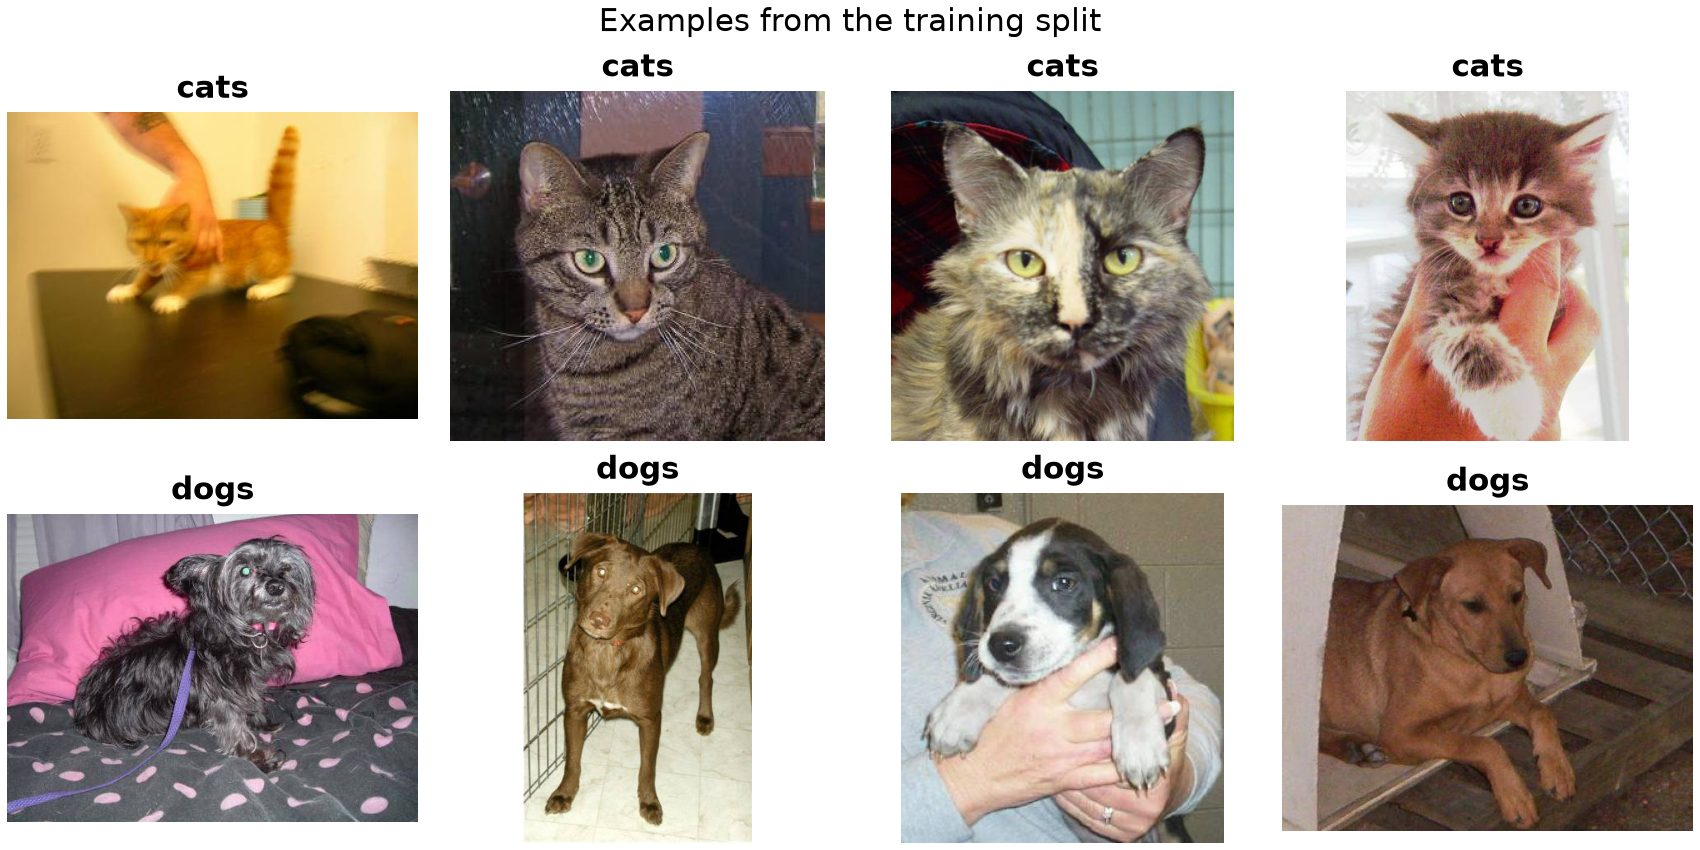

In [5]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.set_num_threads(4)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def seed_worker(_):
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)
    torch.set_num_threads(1)


def preprocessing(name, training=False, size=128):
    if name == 'cnn':
        return transforms.Compose([transforms.Resize((150, 150)), transforms.ToTensor()])
    if name in ('vgg16', 'resnet18'):
        weights = models.VGG16_Weights.IMAGENET1K_V1 if name == 'vgg16' else models.ResNet18_Weights.IMAGENET1K_V1
        return weights.transforms()
    if training:
        return transforms.Compose([
            transforms.RandomResizedCrop(size, scale=(0.65, 1.0), ratio=(0.8, 1.25)),
            transforms.RandomHorizontalFlip(), transforms.ColorJitter(0.15, 0.15, 0.15, 0.03),
            transforms.ToTensor(), transforms.Normalize((0.5,) * 3, (0.5,) * 3)])
    return transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor(),
                                transforms.Normalize((0.5,) * 3, (0.5,) * 3)])


def loader(dataset, batch_size=64, shuffle=False, workers=4, seed=42):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=workers,
                      pin_memory=torch.cuda.is_available(), persistent_workers=workers > 0,
                      worker_init_fn=seed_worker, generator=torch.Generator().manual_seed(seed))


def remove_training_duplicates(dataset, data_root):
    audit_path = ROOT / 'results/data_audit.json'
    if not audit_path.exists():
        raise FileNotFoundError('Run prepare_data.py before training; the duplicate audit is required.')
    audit = json.loads(audit_path.read_text())
    excluded = set()
    for group in audit['duplicate_groups']:
        training = sorted(p for p in group if p.startswith('train/'))
        has_evaluation = any(not p.startswith('train/') for p in group)
        excluded.update(training if has_evaluation else training[1:])
    dataset.samples = [(p, y) for p, y in dataset.samples
                       if Path(p).relative_to(data_root).as_posix() not in excluded]
    dataset.imgs = dataset.samples
    dataset.targets = [y for _, y in dataset.samples]
    return sorted(excluded)


def amp(device):
    return torch.autocast(device_type='cuda', dtype=torch.float16) if device.type == 'cuda' else contextlib.nullcontext()


@torch.inference_mode()
def evaluate(model, batches, device, tta=False):
    model.eval()
    ys, logits = [], []
    for x, y in batches:
        x = x.to(device, non_blocking=True).float()
        with amp(device):
            z = model(x)
            if tta:
                z = (z + model(x.flip(-1))) / 2
        logits.append(z.float().cpu())
        ys.append(y.cpu())
    y, z = torch.cat(ys).float(), torch.cat(logits)
    return dict(loss=nn.functional.binary_cross_entropy_with_logits(z, y).item(),
                accuracy=((z >= 0) == y.bool()).float().mean().item(),
                y=y.numpy(), probabilities=z.sigmoid().numpy())


def extract_features(model, dataset, name, split, device, workers, batch_size):
    cache = ROOT / '.cache' / f'{name}_{split}'
    cache.parent.mkdir(exist_ok=True, parents=True)
    # Cache is tied to exact image bytes/order and preprocessing implementation.
    signature = hashlib.sha256(f"standalone-v1|{name}|IMAGENET1K_V1|resize256-crop224|{torchvision.__version__}".encode())
    for path, label in dataset.samples:
        signature.update(Path(path).read_bytes())
        signature.update(str(label).encode())
    digest = signature.hexdigest()
    marker = cache.with_suffix('.json')
    if marker.exists() and json.loads(marker.read_text())['sha256'] == digest:
        return np.load(cache.with_suffix('.npy'), mmap_mode='r')
    batches = loader(dataset, batch_size=batch_size, workers=workers)
    model.eval()
    features, offset = None, 0
    with torch.inference_mode():
        for x, _ in batches:
            with amp(device):
                f = model.features(x.to(device)).cpu().numpy().astype(np.float16)
            if features is None:
                features = np.lib.format.open_memmap(cache.with_suffix('.npy'), mode='w+',
                                                     dtype='float16', shape=(len(dataset), f.shape[1]))
            features[offset:offset + len(f)] = f
            offset += len(f)
            if offset % (batch_size * 50) == 0:
                print(f'{name}: extracted {split} {offset}/{len(dataset)}', flush=True)
    features.flush()
    marker.write_text(json.dumps(dict(sha256=digest, count=offset)))
    return np.load(cache.with_suffix('.npy'), mmap_mode='r')


class FeatureDataset(Dataset):
    def __init__(self, features, targets):
        self.features, self.targets = features, targets

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        return torch.from_numpy(self.features[index].astype(np.float32)), self.targets[index]


class HeadWrapper(nn.Module):
    def __init__(self, head):
        super().__init__()
        self.head = head

    def forward(self, x):
        return self.head(x).squeeze(1)


def train_run(name, epochs, seed=42, size=128, batch_size=64, workers=4, lr=None,
              data_root=None, run_name=None):
    seed_everything(seed)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    data_root = Path(data_root or ROOT / 'data' / 'Cats_and_Dogs')
    run_name = run_name or name
    output = ROOT / 'results' / run_name
    output.mkdir(parents=True, exist_ok=True)
    checkpoint_dir = ROOT / 'checkpoints'
    checkpoint_dir.mkdir(exist_ok=True)
    train_ds = datasets.ImageFolder(data_root / 'train', preprocessing(name, True, size))
    excluded = remove_training_duplicates(train_ds, data_root)
    val_ds = datasets.ImageFolder(data_root / 'val', preprocessing(name, False, size))
    assert train_ds.class_to_idx == val_ds.class_to_idx
    assert list(train_ds.class_to_idx.values()) == [0, 1]
    pretrained = name in ('vgg16', 'resnet18')
    model = build_model(name, pretrained=pretrained).to(device)
    actual_size = 150 if name == 'cnn' else 224 if pretrained else size
    config = dict(name=name, run_name=run_name, epochs=epochs, seed=seed, image_size=actual_size,
                  batch_size=batch_size, class_to_idx=train_ds.class_to_idx,
                  pretrained=pretrained, train_images=len(train_ds), validation_images=len(val_ds),
                  excluded_training_duplicates=excluded,
                  device=str(device), gpu=torch.cuda.get_device_name(0) if device.type == 'cuda' else None,
                  torch=str(torch.__version__), selection='minimum validation BCE, threshold fixed at 0.5',
                  parameters=sum(p.numel() for p in model.parameters()),
                  trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad))
    if pretrained:
        train_f = extract_features(model, train_ds, name, 'train', device, workers, batch_size)
        val_f = extract_features(model, val_ds, name, 'val', device, workers, batch_size)
        train_batches = loader(FeatureDataset(train_f, train_ds.targets), batch_size=256, shuffle=True, workers=0, seed=seed)
        val_batches = loader(FeatureDataset(val_f, val_ds.targets), batch_size=256, workers=0)
        fit_model = HeadWrapper(model.head)
    else:
        train_batches = loader(train_ds, batch_size, True, workers, seed)
        val_batches = loader(val_ds, batch_size, False, workers, seed)
        fit_model = model
    lr = lr or {'cnn': 0.001, 'vgg16': 0.0001, 'resnet18': 0.001, 'scratch': 0.002}[name]
    config['lr'] = lr
    config['weight_decay'] = 0.0001 if name == 'scratch' else 0.0
    config['augmentation'] = 'random crop, horizontal flip, color jitter; 0.05 label smoothing' if name == 'scratch' else 'none'
    optimizer = torch.optim.AdamW((p for p in fit_model.parameters() if p.requires_grad), lr=lr,
                                   weight_decay=config['weight_decay'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=lr * 0.01) if name == 'scratch' else None
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    best, history, started = math.inf, [], time.perf_counter()
    (output / 'config.json').write_text(json.dumps(config, indent=2))
    print(json.dumps(config), flush=True)
    for epoch in range(1, epochs + 1):
        tic = time.perf_counter()
        fit_model.train()
        total_loss, correct, total = 0.0, 0, 0
        epoch_lr = optimizer.param_groups[0]['lr']
        for x, y in train_batches:
            x, y = x.to(device, non_blocking=True).float(), y.to(device, non_blocking=True).float()
            optimizer.zero_grad(set_to_none=True)
            targets = y * 0.95 + 0.025 if name == 'scratch' else y
            with amp(device):
                z = fit_model(x)
                loss = nn.functional.binary_cross_entropy_with_logits(z, targets)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(fit_model.parameters(), 5.0)
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item() * len(y)
            correct += ((z >= 0) == y.bool()).sum().item()
            total += len(y)
        val = evaluate(fit_model, val_batches, device)
        row = dict(epoch=epoch, train_loss=total_loss / total, train_accuracy=correct / total,
                   val_loss=val['loss'], val_accuracy=val['accuracy'], learning_rate=epoch_lr,
                   seconds=time.perf_counter() - tic)
        history.append(row)
        if val['loss'] < best:
            best = val['loss']
            torch.save(dict(state_dict=model.state_dict(), config=config, best_epoch=epoch,
                            validation_loss=best, validation_accuracy=val['accuracy']),
                       checkpoint_dir / f'{run_name}.pt')
        with (output / 'history.csv').open('w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=list(row))
            writer.writeheader()
            writer.writerows(history)
        print(f"{run_name} {epoch}/{epochs}: train {row['train_accuracy']:.4f}, val {row['val_accuracy']:.4f}, val BCE {val['loss']:.4f}, {row['seconds']:.1f}s", flush=True)
        if scheduler:
            scheduler.step()
    config['training_seconds'] = time.perf_counter() - started
    (output / 'config.json').write_text(json.dumps(config, indent=2))
    return history

In [6]:
def build_model(name, pretrained=False):
    if name == 'cnn':
        return CNNModel()
    if name == 'scratch':
        return ScratchResNet()
    return TransferModel(name, pretrained=pretrained)

### Reading the learning curves
All networks output logits and use `BCEWithLogitsLoss`; sigmoid is applied only when probabilities are needed.
The classification threshold is fixed at 0.5. Minimum validation BCE selects the checkpoint; the last epoch is not automatically selected.
Training metrics include active dropout (and augmentation for the contest model), while validation uses evaluation mode.
Windows uses zero notebook data-loader workers for compatibility; the recorded script run used four. Exact retraining values can differ.

In [7]:
NAMES = {'cnn': 'Required: three-layer CNN', 'vgg16': 'Required: VGG16 transfer',
         'resnet18': 'Required: ResNet18 transfer', 'scratch': '5A CONTEST: residual CNN from scratch'}

def show_history(name):
    if RUN_TRAINING:
        history = pd.read_csv(ROOT / 'results' / name / 'history.csv')
    else:
        history = pd.read_csv(io.StringIO(RECORDED['models'][name]['history_csv']))
    best_epoch = int(history.loc[history.val_loss.idxmin(), 'epoch'])
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
    for ax, metric, label in zip(axes, ['loss', 'accuracy'], ['Binary cross-entropy', 'Accuracy']):
        ax.plot(history.epoch, history['train_' + metric], label='Training', color='#176B87', lw=2)
        ax.plot(history.epoch, history['val_' + metric], label='Validation', color='#E17C37', lw=2)
        ax.axvline(best_epoch, color='#777777', ls=':', label=f'Selected epoch {best_epoch}')
        ax.set(xlabel='Epoch', ylabel=label, title=label)
        ax.legend(fontsize=8)
    fig.suptitle(NAMES[name])
    plt.show()
    plt.close(fig)
    print(f'{name}: {len(history)} epochs; selected checkpoint = epoch {best_epoch}')
    display(history.tail(3).round(5))

<a id="part1"></a>
## Part 1 — REQUIRED: three-layer CNN
**هذا أول جزء من الواجب الأساسي، وهو من تنفيذنا وتدريبنا.**

We completed the course architecture: convolutional channels 16 -> 32 -> 64, 3×3 kernels,
ReLU and 2×2 max pooling after each convolution. At 150×150 input, pooling gives 75 -> 37 -> 18 pixels.
Flattening produces 20,736 features, followed by 64 hidden units, dropout 0.5 and one logit.
Pixels are scaled to [0,1]. Training uses 15 epochs, learning rate 0.001, batch size 128, seed 42.
AdamW with zero weight decay is equivalent here to Adam.

In [8]:
class CNNModel(nn.Module):
    """The exact three-convolution, 150 x 150 course baseline."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 18 * 18, 64),
                                  nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, 1))

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

Parameters: 1350817
Output shape: (2,)


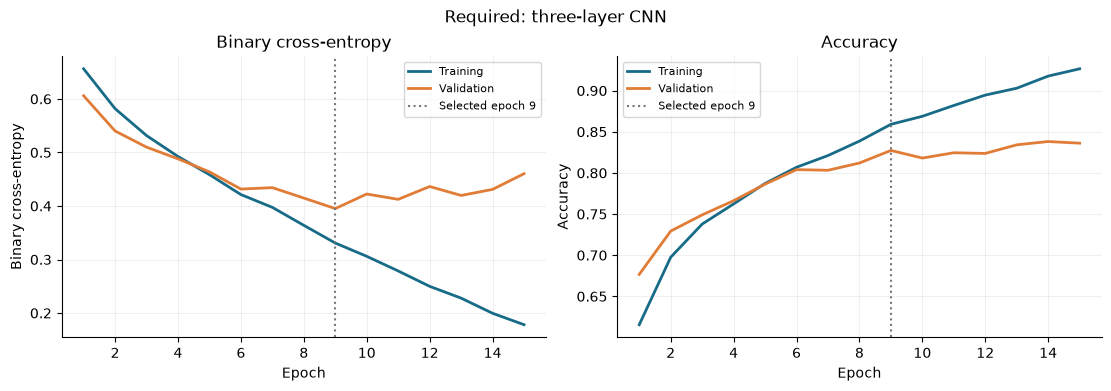

cnn: 15 epochs; selected checkpoint = epoch 9


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,seconds
12,13,0.22782,0.90293,0.41966,0.83414,0.001,9.97301
13,14,0.19954,0.91768,0.43100,0.83815,0.001,10.13380
14,15,0.17819,0.92653,0.46035,0.83614,0.001,10.65686


In [9]:
baseline = CNNModel()
print('Parameters:', sum(p.numel() for p in baseline.parameters()))
print('Output shape:', tuple(baseline(torch.zeros(2, 3, 150, 150)).shape))
del baseline
if RUN_TRAINING:
    train_run('cnn', epochs=15, batch_size=128, workers=WORKERS)
show_history('cnn')

**Recorded test result: 2,054 / 2,500 correct = 82.16%.** The selected checkpoint is epoch 9.
Later epochs increased training accuracy but worsened validation BCE, so the final epoch was not used.
The recorded scores in explanatory text refer to the submitted run; a fresh run produces its own final table below.

<a id="part2"></a>
## Part 2 — REQUIRED: VGG16 and ResNet18 transfer learning
**هذا الجزء الثاني من الواجب الأساسي. استخدمنا ميزات مدرّبة مسبقًا ودرّبنا طبقات التصنيف الجديدة.**

Both backbones use explicit torchvision `IMAGENET1K_V1` weights and the official preprocessing:
resize the shorter edge to 256, center crop to 224, convert to a tensor, and normalize with ImageNet mean/std.
VGG16 uses the requested 25,088 -> 256 -> 1 head; ResNet18 uses 512 -> 256 -> 1. Both heads use ReLU and dropout 0.5.
The backbone weights are frozen, and ResNet BatchNorm statistics remain frozen through evaluation mode.

Because preprocessing is deterministic and the backbone never changes, features are extracted once and cached in float16.
They are promoted to float32 for head training; the small float16 approximation is documented.
**These pretrained models satisfy Part 2, but they are not eligible for Part 3.**

In [10]:
class TransferModel(nn.Module):
    def __init__(self, architecture, pretrained=True):
        super().__init__()
        if architecture == 'vgg16':
            net = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1 if pretrained else None)
            self.features = nn.Sequential(net.features, nn.AdaptiveAvgPool2d((7, 7)), nn.Flatten())
            self.head = nn.Sequential(nn.Linear(512 * 7 * 7, 256), nn.ReLU(),
                                      nn.Dropout(0.5), nn.Linear(256, 1))
        elif architecture == 'resnet18':
            net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
            self.features = nn.Sequential(*list(net.children())[:-1], nn.Flatten())
            self.head = nn.Sequential(nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 1))
        else:
            raise ValueError(architecture)
        self.features.requires_grad_(False)

    def train(self, mode=True):
        super().train(mode)
        # Freezing parameters alone does not freeze ResNet's BatchNorm statistics.
        self.features.eval()
        return self

    def forward(self, x):
        with torch.no_grad():
            features = self.features(x)
        return self.head(features).squeeze(1)

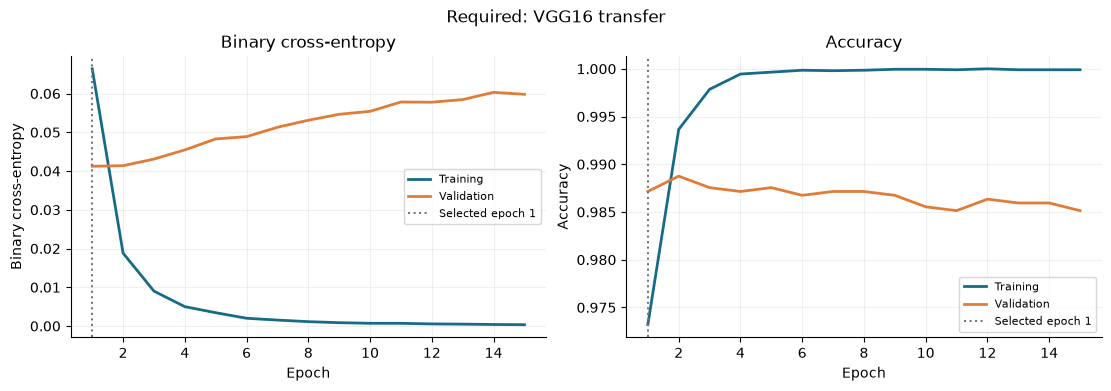

vgg16: 15 epochs; selected checkpoint = epoch 1


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,seconds
12,13,0.00049,0.9999,0.05844,0.98594,0.0001,2.19890
13,14,0.00040,0.9999,0.06031,0.98594,0.0001,2.10032
14,15,0.00034,0.9999,0.05980,0.98514,0.0001,2.30166


In [11]:
# VGG16: train the new head for 15 epochs, learning rate 0.0001.
if RUN_TRAINING:
    train_run('vgg16', epochs=15, batch_size=64, workers=WORKERS)
show_history('vgg16')

**VGG16 recorded test result: 2,458 / 2,500 correct = 98.32%.** The validation-selected epoch is 1.

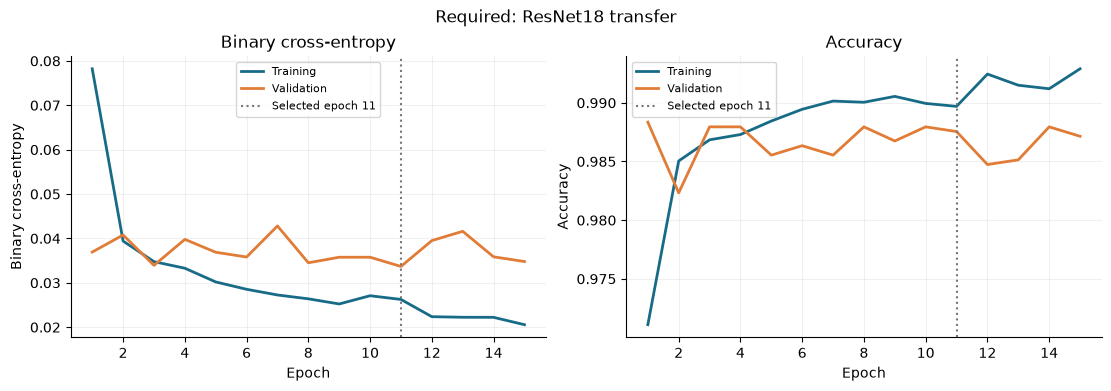

resnet18: 15 epochs; selected checkpoint = epoch 11


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,seconds
12,13,0.02224,0.9915,0.04160,0.98514,0.001,0.36401
13,14,0.02222,0.9912,0.03586,0.98795,0.001,0.45054
14,15,0.02056,0.9929,0.03480,0.98715,0.001,0.38625


In [12]:
# ResNet18: a different pretrained architecture, with a new head trained at 0.001.
if RUN_TRAINING:
    train_run('resnet18', epochs=15, batch_size=64, workers=WORKERS)
show_history('resnet18')

**ResNet18 recorded test result: 2,464 / 2,500 correct = 98.56%.** Epoch 11 had the lowest validation BCE. ResNet18 was selected for custom-image inference using validation data, before test evaluation.

<a id="part3"></a>
## Part 3 — OPTIONAL 5A CONTEST: our model trained from scratch
**هذا هو شغل مسابقة الـ5A تحديدًا: النموذج التالي تعلّم من الصفر، بدون أي أوزان مدرّبة مسبقًا.**

We designed a compact residual CNN with 32/64/128/256 channels, global average pooling and dropout 0.2.
Every convolution starts from random Kaiming initialization. Residual connections help gradients propagate.
This model never uses ImageNet weights, pretrained cached features, teacher predictions or a pretrained ensemble member.

Training recipe: 60 epochs, 128×128 images, batch size 128, seed 42, random resized crops,
horizontal flips, mild color jitter, AdamW (initial learning rate 0.002, weight decay 0.0001), and cosine decay.
Normalization uses fixed mean/std 0.5. Label smoothing maps targets to 0.025 and 0.975 during training;
validation/test BCE uses hard labels, so their loss curves are not directly identical objectives.

The best checkpoint was selected by validation BCE. Original-image inference was then compared with
averaging the original and horizontally flipped logits on validation data only.

In [13]:
class ResidualBlock(nn.Module):
    def __init__(self, inputs, outputs, stride=1):
        super().__init__()
        self.main = nn.Sequential(nn.Conv2d(inputs, outputs, 3, stride, 1, bias=False),
                                  nn.BatchNorm2d(outputs), nn.ReLU(),
                                  nn.Conv2d(outputs, outputs, 3, padding=1, bias=False),
                                  nn.BatchNorm2d(outputs))
        self.skip = nn.Identity() if inputs == outputs and stride == 1 else nn.Sequential(
            nn.Conv2d(inputs, outputs, 1, stride, bias=False), nn.BatchNorm2d(outputs))

    def forward(self, x):
        return torch.relu(self.main(x) + self.skip(x))


class ScratchResNet(nn.Module):
    """Compact residual network: random initialization only; no external weights."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
            ResidualBlock(32, 32), ResidualBlock(32, 64, 2),
            ResidualBlock(64, 128, 2), ResidualBlock(128, 128),
            ResidualBlock(128, 256, 2), ResidualBlock(256, 256),
            nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(256, 1))
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

Contest parameters, all trainable: 2702753


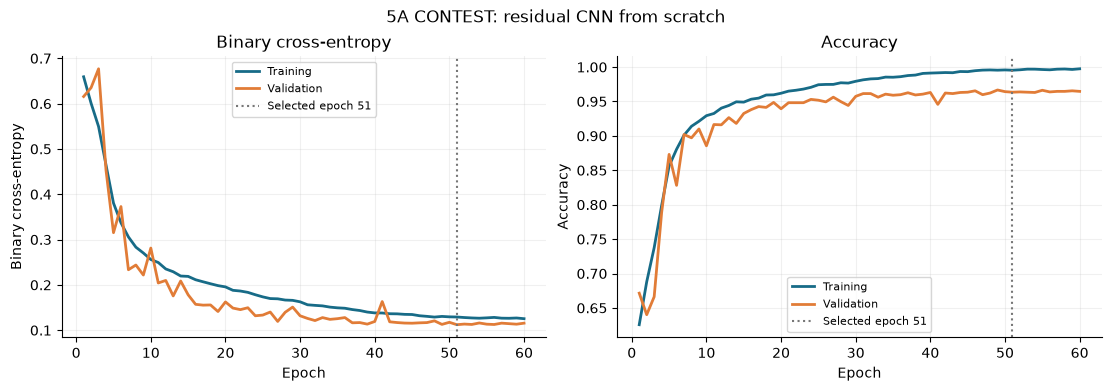

scratch: 60 epochs; selected checkpoint = epoch 51


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate,seconds
57,58,0.12636,0.99715,0.11447,0.96466,0.00003,14.83129
58,59,0.12700,0.99650,0.11334,0.96546,0.00003,14.79804
59,60,0.12547,0.99745,0.11559,0.96466,0.00002,14.80743


In [14]:
contest_model = ScratchResNet()
assert all(p.requires_grad for p in contest_model.parameters())
print('Contest parameters, all trainable:', sum(p.numel() for p in contest_model.parameters()))
del contest_model
if RUN_TRAINING:
    train_run('scratch', epochs=60, size=128, batch_size=128, workers=WORKERS)
show_history('scratch')

**Contest result: 2,408 / 2,500 correct = 96.32%.** Epoch 51 was selected.
Flip averaging reduced validation BCE from 0.11219 to 0.10272 and was therefore used for the contest test score.
This score is eligible under the no-pretrained-weights rule. The course's automatic 5A award goes to the highest-scoring contestant;
other students' results are unknown, so this submission does not claim a winning rank.

## Final evaluation — shared by the required work and the contest
The following code locks validation decisions **before** evaluating any test images.
It saves per-image probabilities, class metrics and checkpoint hashes when retraining.
In review mode, the same tables and confusion matrices are reconstructed from embedded measurements.

In [15]:
def load_classifier(checkpoint, device=None):
    device = torch.device(device or ('cuda' if torch.cuda.is_available() else 'cpu'))
    saved = torch.load(checkpoint, map_location='cpu', weights_only=True)
    model = build_model(saved['config']['name'], pretrained=False)
    model.load_state_dict(saved['state_dict'])
    model.to(device).eval()
    return model, saved['config'], device


@torch.inference_mode()
def predict_image(image_path, model, config, device, tta=False):
    """Return the class, both class probabilities and confidence (not calibration)."""
    with Image.open(image_path) as image:
        image = ImageOps.exif_transpose(image).convert('RGB')
        x = preprocessing(config['name'], size=config['image_size'])(image).unsqueeze(0).to(device)
    model.eval()
    with amp(device):
        z = model(x)
        if tta:
            z = (z + model(x.flip(-1))) / 2
    p = z.float().sigmoid().item()
    names = {value: key for key, value in config['class_to_idx'].items()}
    index = int(p >= 0.5)
    return dict(predicted_class=names[index], confidence=p if index else 1 - p,
                probabilities={names[0]: 1 - p, names[1]: p})

In [16]:
def wilson(correct, total):
    z = 1.959963984540054
    p = correct / total
    d = 1 + z*z / total
    center = (p + z*z / (2*total)) / d
    half = z * math.sqrt(p*(1-p)/total + z*z/(4*total*total)) / d
    return center-half, center+half


def evaluate_all():
    seed_everything(42)
    paths = sorted((ROOT / 'checkpoints').glob('*.pt'))
    selections = {}
    for path in paths:
        saved = torch.load(path, map_location='cpu', weights_only=True)
        selections[path.stem] = dict(name=saved['config']['name'],
                                     best_epoch=saved['best_epoch'],
                                     validation_loss=saved['validation_loss'],
                                     validation_accuracy=saved['validation_accuracy'],
                                     checkpoint_sha256=hashlib.sha256(path.read_bytes()).hexdigest())
    # Test-time augmentation for the contest is selected solely on validation BCE.
    for key, selected in selections.items():
        selected['tta'] = False
        if selected['name'] == 'scratch':
            model, config, device = load_classifier(ROOT / 'checkpoints' / f'{key}.pt')
            val_ds = datasets.ImageFolder(ROOT / 'data/Cats_and_Dogs/val', preprocessing('scratch', size=config['image_size']))
            batches = loader(val_ds, workers=WORKERS)
            plain = evaluate(model, batches, device)
            tta = evaluate(model, batches, device, tta=True)
            selected['validation_plain_loss'] = plain['loss']
            selected['validation_tta_loss'] = tta['loss']
            selected['tta'] = tta['loss'] < plain['loss']
            selected['validation_loss'] = min(plain['loss'], tta['loss'])
            selected['validation_accuracy'] = tta['accuracy'] if selected['tta'] else plain['accuracy']
            del model, batches
            torch.cuda.empty_cache()
    best = min(selections, key=lambda k: selections[k]['validation_loss'])
    locked = dict(best_inference_model=best, selection_rule='lowest validation BCE before test access', models=selections)
    (ROOT / 'results/selection.json').write_text(json.dumps(locked, indent=2))
    rows = []
    for key, selected in selections.items():
        model, config, device = load_classifier(ROOT / 'checkpoints' / f'{key}.pt')
        test_ds = datasets.ImageFolder(ROOT / 'data/Cats_and_Dogs/test', preprocessing(config['name'], size=config['image_size']))
        assert test_ds.class_to_idx == config['class_to_idx']
        result = evaluate(model, loader(test_ds, workers=WORKERS), device, tta=selected['tta'])
        y, p = result['y'].astype(int), result['probabilities']
        pred = (p >= 0.5).astype(int)
        correct = int((pred == y).sum())
        low, high = wilson(correct, len(y))
        row = dict(model=key, pretrained=config['pretrained'], best_epoch=selected['best_epoch'],
                   validation_loss=selected['validation_loss'], test_loss=result['loss'],
                   accuracy=accuracy_score(y,pred), balanced_accuracy=balanced_accuracy_score(y,pred),
                   f1_dog=f1_score(y,pred), roc_auc=roc_auc_score(y,p), correct=correct,
                   test_images=len(y), ci95_low=low, ci95_high=high, tta=selected['tta'])
        rows.append(row)
        dest = ROOT / 'results' / key
        pd.DataFrame(dict(path=[Path(x[0]).relative_to(ROOT / 'data/Cats_and_Dogs').as_posix() for x in test_ds.samples],
                          target=y, probability_dog=p, prediction=pred)).to_csv(dest / 'test_predictions.csv', index=False)
        report = classification_report(y,pred,target_names=test_ds.classes,output_dict=True)
        report['confusion_matrix'] = confusion_matrix(y,pred).tolist()
        (dest / 'test_metrics.json').write_text(json.dumps(dict(**row, classification_report=report), indent=2))
        print(json.dumps(row), flush=True)
        del model
        torch.cuda.empty_cache()
    pd.DataFrame(rows).to_csv(ROOT / 'results/comparison.csv', index=False)
    model, config, device = load_classifier(ROOT / 'checkpoints' / f'{best}.pt')
    custom = []
    for path in sorted((ROOT / 'custom_images').glob('*')):
        if path.suffix.lower() in {'.jpg','.jpeg','.png'}:
            custom.append(dict(image=path.name, **predict_image(path, model, config, device, tta=selections[best]['tta'])))
    (ROOT / 'results/custom_predictions.json').write_text(json.dumps(dict(model=best,predictions=custom), indent=2))

In [17]:
if RUN_TRAINING:
    evaluate_all()
    comparison = pd.read_csv(ROOT / 'results/comparison.csv')
    selection = json.loads((ROOT / 'results/selection.json').read_text())
    metrics = {name: json.loads((ROOT / 'results' / name / 'test_metrics.json').read_text())
               for name in ['cnn', 'vgg16', 'resnet18', 'scratch']}
else:
    comparison = pd.read_csv(io.StringIO(RECORDED['comparison_csv']))
    selection = RECORDED['selection']
    metrics = {name: item['metrics'] for name, item in RECORDED['models'].items()}

for name, item in metrics.items():
    cm = np.array(item['classification_report']['confusion_matrix'])
    assert cm.sum() == 2500
    assert abs(cm.trace() / cm.sum() - item['accuracy']) < 1e-10

order = ['cnn', 'vgg16', 'resnet18', 'scratch']
comparison = comparison.set_index('model').loc[order].reset_index()
display(comparison[['model','pretrained','best_epoch','accuracy','test_loss','roc_auc','tta']]
        .style.format({'accuracy':'{:.2%}', 'test_loss':'{:.4f}', 'roc_auc':'{:.4f}'}))
print('Custom-image model selected by validation BCE:', selection['best_inference_model'])
print('5A contest model: scratch. Pretrained models are excluded from the contest.')

,model,pretrained,best_epoch,accuracy,test_loss,roc_auc,tta
0,cnn,False,9,82.16%,0.3842,0.9077,False
1,vgg16,True,1,98.32%,0.0481,0.9984,False
2,resnet18,True,11,98.56%,0.0433,0.9986,False
3,scratch,False,51,96.32%,0.1137,0.9912,True


Custom-image model selected by validation BCE: resnet18
5A contest model: scratch. Pretrained models are excluded from the contest.


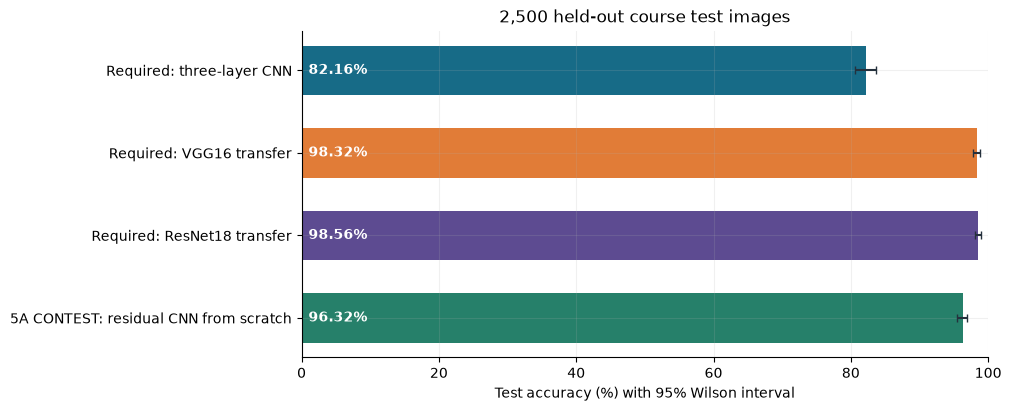

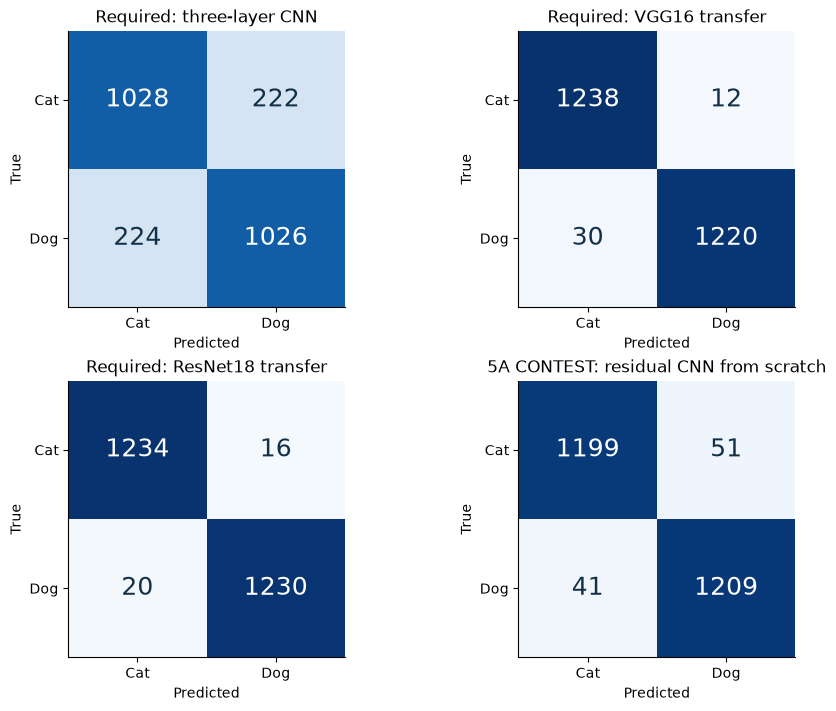

In [18]:
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
x = comparison.accuracy.to_numpy() * 100
y = np.arange(len(comparison))
errors = np.array([x - comparison.ci95_low.to_numpy()*100, comparison.ci95_high.to_numpy()*100 - x])
ax.barh(y, x, color=['#176B87','#E17C37','#5D4B91','#26806A'], height=.6)
ax.errorbar(x, y, xerr=errors, fmt='none', ecolor='#25313D', capsize=3)
for i, value in enumerate(x): ax.text(1, i, f'{value:.2f}%', va='center', color='white', weight='bold')
ax.set(yticks=y, yticklabels=[NAMES[n] for n in comparison.model], xlim=(0,100),
       xlabel='Test accuracy (%) with 95% Wilson interval', title='2,500 held-out course test images')
ax.invert_yaxis()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(9, 7), layout='constrained')
for ax, name in zip(axes.flat, order):
    cm = np.array(metrics[name]['classification_report']['confusion_matrix'])
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=1250)
    for i in range(2):
        for j in range(2):
            ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=18,
                    color='white' if cm[i,j]>600 else '#123047')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Cat','Dog'],yticklabels=['Cat','Dog'],
           xlabel='Predicted',ylabel='True',title=NAMES[name])
    ax.grid(False)
plt.show()
plt.close(fig)

### Recorded error analysis

Most confident mistakes of the validation-selected ResNet18 from the recorded run. Several images contain both a cat and a dog; other examples involve small subjects or low light. The original labels were kept. This inspection happened after fitting and was not used to tune against the test set.

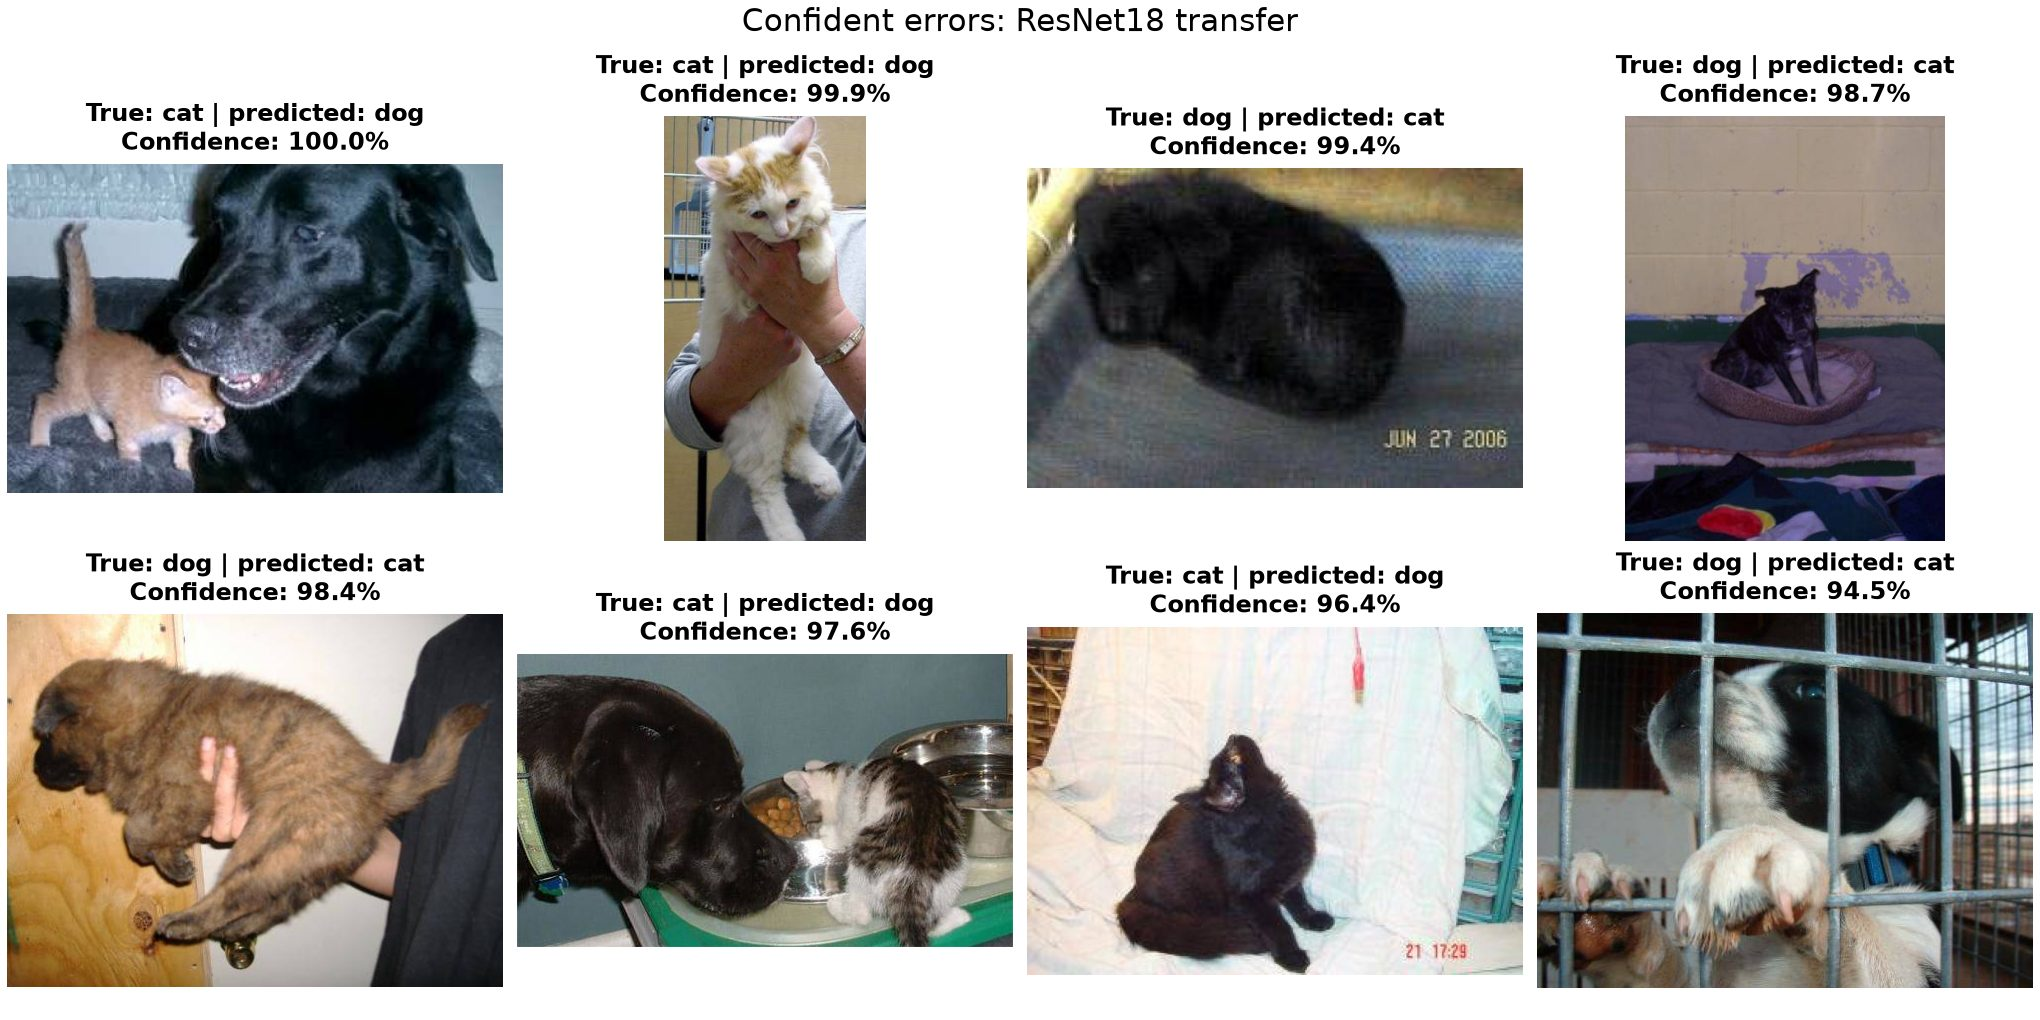

<a id="custom"></a>
## Custom-image inference — completing Part 2
The photograph below comes from [PyTorch Hub](https://github.com/pytorch/hub/blob/master/images/dog.jpg),
outside the course archive. Its file and decoded-pixel hashes were checked against all course images with no exact match.
Possible overlap with ImageNet is unknown. One custom image demonstrates the pipeline; it is not another accuracy benchmark.

`predict_image` above handles EXIF orientation, RGB conversion, the checkpoint's preprocessing and class mapping.
The next helper downloads the selected checkpoint only when new inference is enabled, verifies its SHA-256, and never loads a project Python file.

### Embedded custom photograph

Recorded prediction: **dog**, with model confidence **88.40%**. Confidence is not a calibration guarantee.

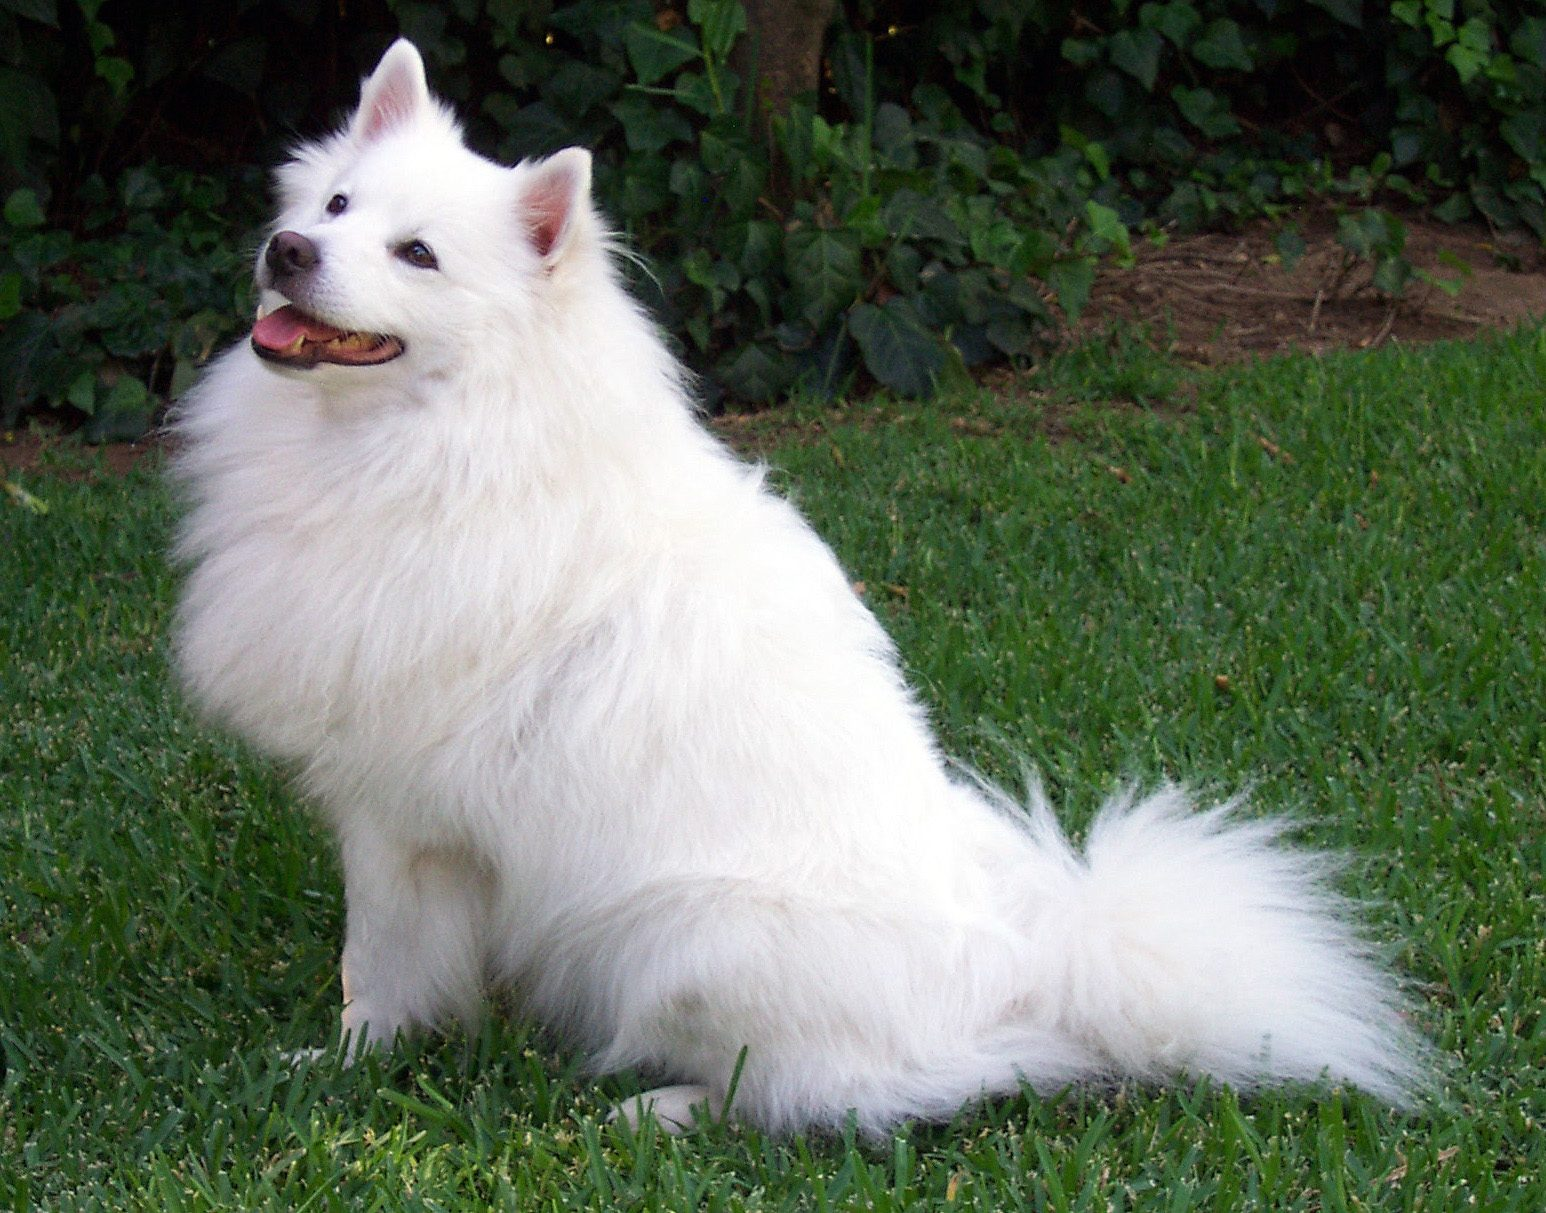

In [19]:
def download_recorded_checkpoint(name):
    entry = RECORDED['checkpoints'][name + '.pt']
    path = ROOT / 'checkpoints' / (name + '.pt')
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists() or hashlib.sha256(path.read_bytes()).hexdigest() != entry['sha256']:
        temp = path.with_suffix('.download')
        urllib.request.urlretrieve(entry['url'], temp)
        if hashlib.sha256(temp.read_bytes()).hexdigest() != entry['sha256']:
            raise ValueError('Checkpoint checksum mismatch')
        temp.replace(path)
    return path

if RUN_CUSTOM_INFERENCE or RUN_TRAINING:
    best = selection['best_inference_model']
    checkpoint = ROOT / 'checkpoints' / f'{best}.pt' if RUN_TRAINING else download_recorded_checkpoint(best)
    if CUSTOM_IMAGE_PATH is None:
        image_path = ROOT / 'custom_images' / 'dog.jpg'
        image_path.parent.mkdir(parents=True, exist_ok=True)
        if not image_path.exists():
            urllib.request.urlretrieve('https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg', image_path)
        assert hashlib.sha256(image_path.read_bytes()).hexdigest() == 'f3f87bb8ab3c26c7ecfd3ac60421d7f32b0503d1d6c5baf8bac42ed93d86351a'
    else:
        image_path = Path(CUSTOM_IMAGE_PATH)
    model, config, device = load_classifier(checkpoint)
    prediction = predict_image(image_path, model, config, device, tta=selection['models'][best]['tta'])
    print('Newly computed inference:', json.dumps(prediction, indent=2))
    del model
    torch.cuda.empty_cache()
else:
    prediction = RECORDED['custom']['predictions'][0]
    print('Saved inference from the actual run:', json.dumps(prediction, indent=2))

Saved inference from the actual run: {
  "image": "dog.jpg",
  "predicted_class": "dogs",
  "confidence": 0.8840392827987671,
  "probabilities": {
    "cats": 0.11596071720123291,
    "dogs": 0.8840392827987671
  }
}


## Conclusions and explanation for the defense

- **Required work:** a three-layer CNN, VGG16 transfer learning, another pretrained model (ResNet18), test accuracies, learning curves, and custom-image inference are all implemented in this notebook.
- **Our optional contest work:** the residual CNN in Part 3 is trained entirely from scratch and scores **96.32%** on the supplied test split.
- **Why transfer learning helps:** the backbone already learned useful visual patterns from a much larger dataset. Its advantage cannot be attributed only to architecture because the upstream data budget differs.
- **Why not select the final epoch:** training accuracy can rise while validation loss worsens. BCE also penalizes confident mistakes, so the best-loss epoch can differ from the best-accuracy epoch.
- **Why validation may look better than training:** dropout and augmentation make training harder; training metrics are collected while weights change. The contest training BCE also uses smoothed labels.
- **Why frozen BatchNorm matters:** setting `requires_grad=False` alone does not stop BatchNorm statistics from changing. Keeping the backbone in eval mode does.
- **Why remove duplicates:** identical images across training and evaluation can inflate scores through memorization. Evaluation images were kept; redundant training copies were removed.
- **Limits:** one seed per architecture, a duplicated test photo, and unknown class ranking. Wilson intervals describe approximate test-sample uncertainty, not training-seed variability or paired significance.
- **Further contest improvements:** higher-resolution training and validation-selected ensembles of independently trained scratch models could be explored. They have not been measured here. No pretrained member may enter such an ensemble, and the test set must not become a tuning set.

**شو لازم تعمل للتسليم؟** سلّم هذا الـNotebook أو رابطه. راجع Part 1 وPart 2 للواجب، وPart 3 للمسابقة.
أكد مع المدرّس تسجيل نتيجة 96.32% في المسابقة. الوصول إلى الـ5A التلقائية يتطلب أعلى نتيجة مؤهلة؛ لا يمكن إثبات الفوز من نتيجتنا وحدها.

Sources: supplied Task 4 PDF, lecture 7 and course PyTorch notebook;
[course dataset](https://drive.google.com/drive/folders/1KpT0oBIb3aDaBtjf7Hs4WAUPoFEpbsYr),
[VGG16 documentation](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.vgg16.html),
[ResNet18 documentation](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html).